In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

question 01


In [ ]:
df=pd.read_csv('adult_income.csv')
print(df.shape)
print(df.info())
print(df.head())
print(df.describe())

print(df.isnull().sum())

(48842, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       48842 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      48842 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hours-per-week  48842 non-null  int64 
 13  native-country  48842 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB
None
   age          workclass  fnlwgt   education  education-num  \
0   39      

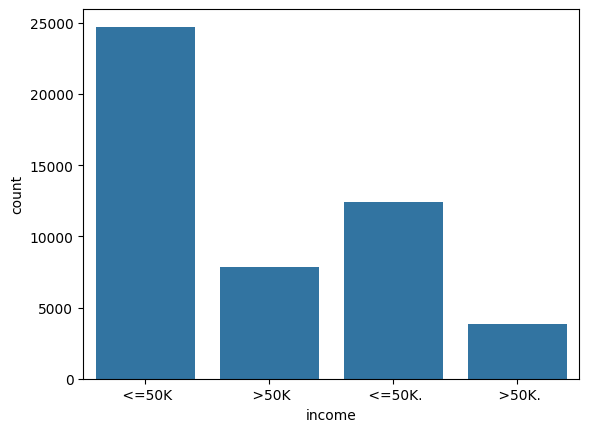

In [ ]:
sns.countplot(x='income',data=df)
plt.show()

In [ ]:
df['income'].unique()

array([' <=50K', ' >50K', ' <=50K.', ' >50K.'], dtype=object)

In [ ]:
df['income'] = df['income'].astype(str).str.strip()
df['income'] = df['income'].str.replace('.', '', regex=False)
df['income'] = df['income'].map({
    '<=50K': 0,
    '>50K': 1
})


In [ ]:
df.corr(numeric_only=True)['income'].sort_values(ascending=False)

,income
income,1.000000
income_num,1.000000
education-num,0.332613
age,0.230369
hours-per-week,0.227687
capital-gain,0.223013
capital-loss,0.147554
fnlwgt,-0.006339


 age, capital-gain, education num horsse besi relation income er sathe numeric value er morddhe....

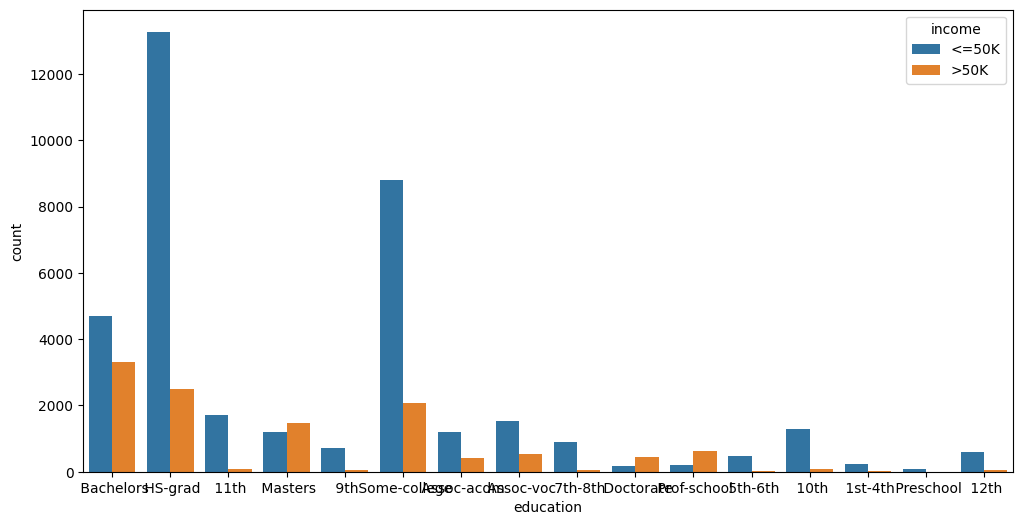

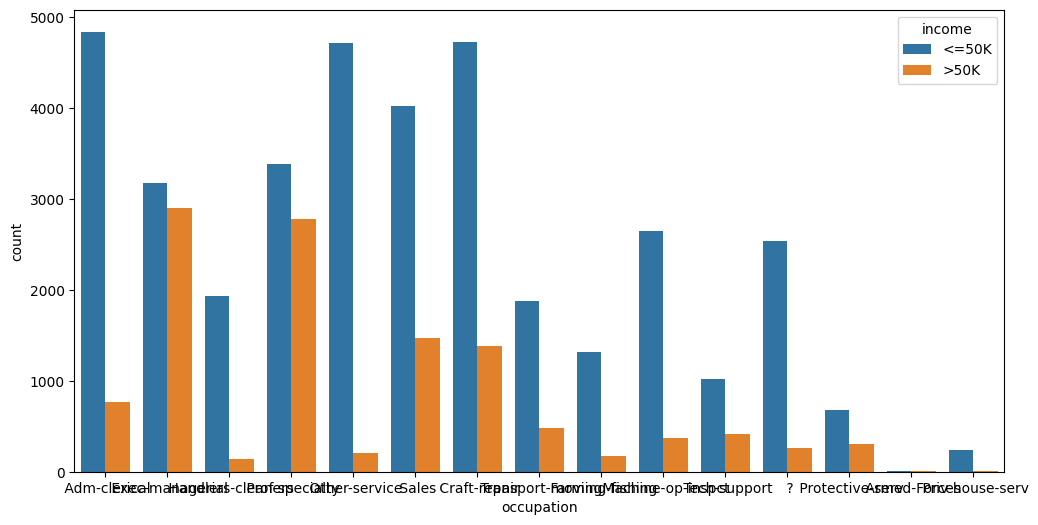

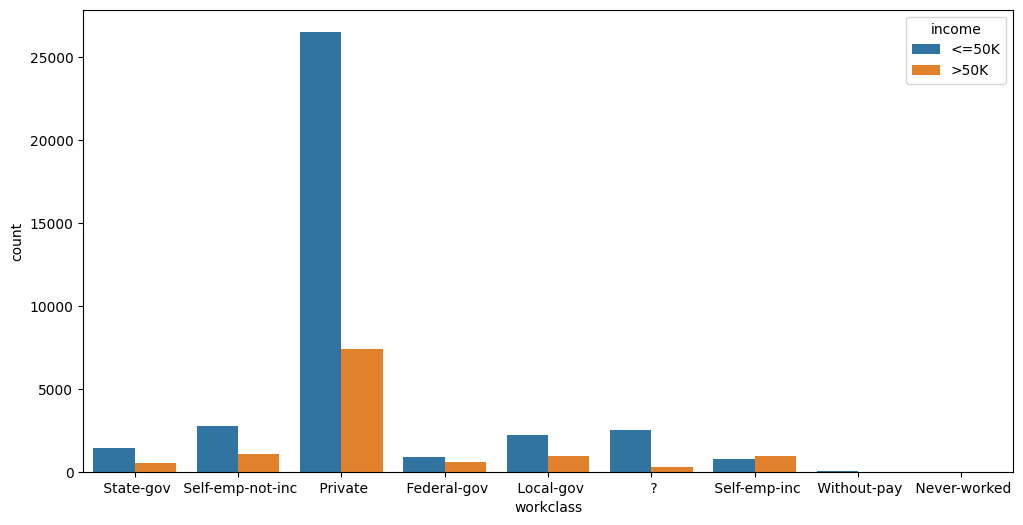

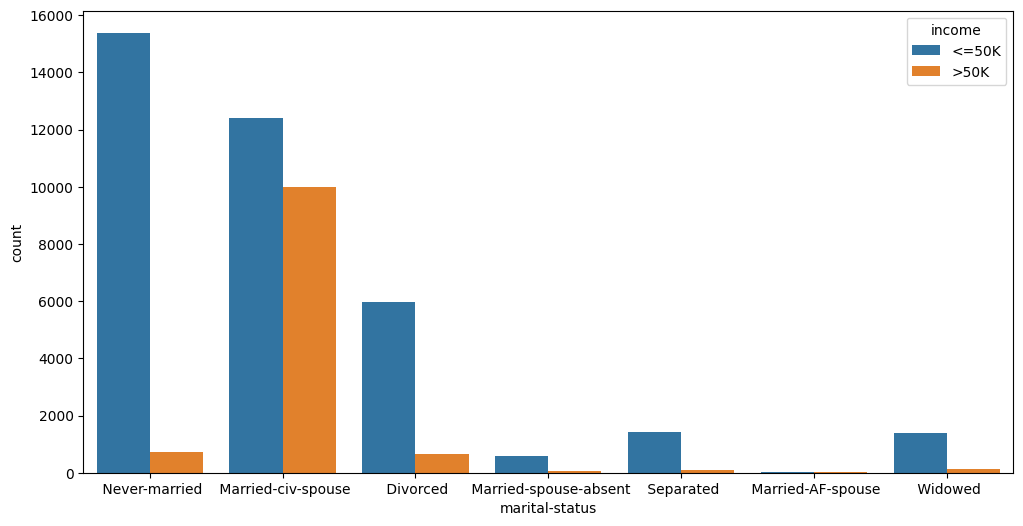

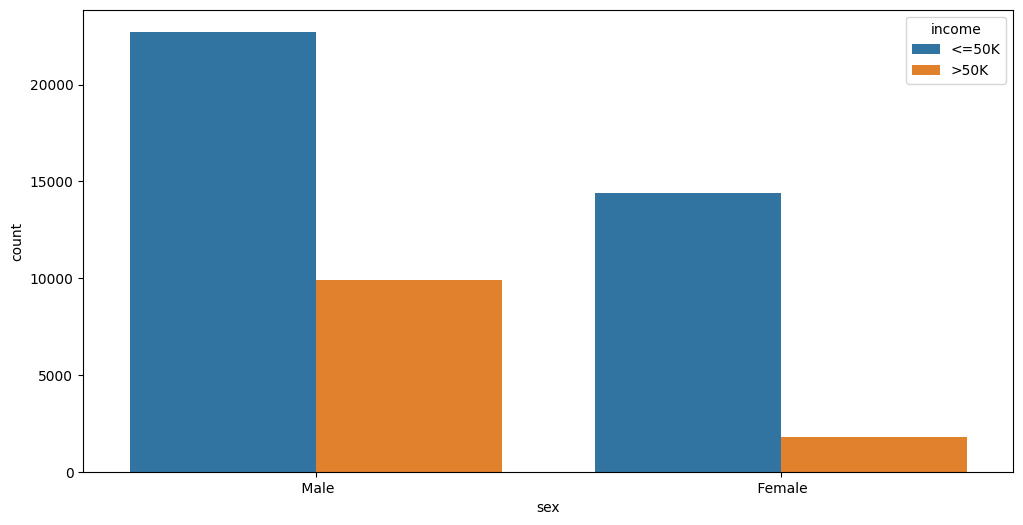

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

cat_features = [
    'education',
    'occupation',
    'workclass',
    'marital-status',
    'sex'
]
for col in cat_features:

    plt.figure(figsize=(12,6))

    sns.countplot(
        x=col,
        hue='income',
        data=df
    )

    plt.show()

TOP 3 feature selected:

1. capital-gain : because correlation is high
2. age :because correlation is high ..
3. Education Level: Countplot shows higher education groups have more >50K earners

rank 1: Education (Higher education helps people get better-paying jobs.)

rank2: age(More age usually means more work experience.)

rank3: capital-gain(eople with investments or business profits usually earn more)

# Question 2: Preprocessing Pipeline Design (Regression) - 20

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder

df.columns = df.columns.str.strip()
x=df.drop("hours-per-week",axis=1)
y=df['hours-per-week']

numeric_column=x.select_dtypes(
    include=['int64','float64']
).columns
categorical_coloum=x.select_dtypes(
    include=['object']
).columns
numeric =Pipeline(
    steps=[
        ('imputer',SimpleImputer(strategy='median')),
        ('scaler',StandardScaler())
    ]
)

categorical =Pipeline(
    steps=[
        ('importe',SimpleImputer(strategy='most_frequent')),
        ('onehot',OneHotEncoder(sparse_output=True,handle_unknown='ignore'))
    ]
)
preprocessor=ColumnTransformer(
     transformers=[
         ('num',numeric,numeric_column),
         ('cat',categorical,categorical_coloum)
     ],
     remainder='passthrough'
 )

In [ ]:
numeric

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])

In [ ]:
categorical


Pipeline(steps=[('importe', SimpleImputer(strategy='most_frequent')),
                ('onehot', OneHotEncoder(handle_unknown='ignore'))])

In [ ]:
preprocessor

ColumnTransformer(remainder='passthrough',
                  transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 Index(['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss',
       'income_num'],
      dtype='object')),
                                ('cat',
                                 Pipeline(steps=[('importe',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country', 'income'],
      dtype='object'))])

# numeric e missing value r jonno simple importer er diye medium diye add korbo er por StandardScaling diye sobai k ek scale e niye asha hobe karon boro value er feature choto maner value r upor chap nh dey,,

# categorical e OneHotEnoder use kora hoise karon sob categorical value k numerical 0 and 1 e niye asha

## **Question 3: Regression Modeling & Evaluation**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error, r2_score,mean_absolute_error
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)


liner_model=Pipeline(
    steps=[
        ('preprosessor',preprocessor),
        ('model',LinearRegression())
    ]
)
liner_model.fit(x_train,y_train)
liner_predict = liner_model.predict(x_test)

sgd_model=Pipeline(
    steps=[
        ('preprocessor',preprocessor),
        ('model',SGDRegressor(random_state=42))
    ]
)
sgd_model.fit(x_train,y_train)
sgd_predict=sgd_model.predict(x_test)

In [ ]:
liner_model

Pipeline(steps=[('preprosessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss',
       'income_num'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('importe',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country', 'income'],
      dtype='object'))])),
                ('model', LinearRegression())])

In [ ]:
sgd_model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss',
       'income_num'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('importe',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country', 'income'],
      dtype='object'))])),
                ('model', SGDRegressor(random_state=42))])

In [ ]:
#Evaluation

print("Linear Regression :\n")
print(r2_score(y_test,liner_predict))
print(mean_squared_error(y_test,liner_predict))
print(mean_absolute_error(y_test,liner_predict))

print("\nSGD Regression :\n")
print(r2_score(y_test,sgd_predict))
print(mean_squared_error(y_test,sgd_predict))
print(mean_absolute_error(y_test,sgd_predict))


Linear Regression :

0.20153904369769648
122.41843360357242
7.657295835747004

SGD Regression :

0.20171431240501325
122.39156175662727
7.636794356571338


**Question 4: Classification Pipeline & Error Analysis -20**

In [ ]:
from sklearn.linear_model import LogisticRegression

y1 = df['income']
x1 = df.drop(['income'], axis=1)
numeric_column_clf = x1.select_dtypes(include=['int64', 'float64']).columns
categorical_coloum_clf = x1.select_dtypes(include=['object']).columns

preprocessor_clf = ColumnTransformer(
    transformers=[
        ('num', numeric, numeric_column_clf),
        ('cat', categorical, categorical_coloum_clf)
    ],
    remainder='passthrough'
)
x1_train, x1_test, y1_train, y1_test = train_test_split(x1, y1, test_size=0.2, random_state=42)

classification_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor_clf),
        ('model', LogisticRegression(class_weight='balanced', max_iter=1000))
    ]
)

classification_pipeline.fit(x1_train, y1_train)
classification_predict = classification_pipeline.predict(x1_test)

In [ ]:
classification_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss',
       'hours-per-week', 'income_num'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('importe',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country'],
      dtype='object'))])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [ ]:
from sklearn.metrics import accuracy_score,precision_score,recall_score
print(accuracy_score(y1_test,classification_predict))
print(precision_score(y1_test,classification_predict))
print(recall_score(y1_test,classification_predict))

1.0
1.0
1.0


## *Question 5: Hyperparameter Tuning & Model Comparison*

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

knn_pipeline = Pipeline([
    ('preprocessing', preprocessor_clf),
    ('knn', KNeighborsClassifier())
])

grid = {
    'knn__n_neighbors': [3,5,7,9],
    'knn__weights': ['uniform','distance'],
    'knn__metric': ['euclidean','manhattan']
}

grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=grid,
    cv=5,
    n_jobs=-1
)

grid_search.fit(x1_train, y1_train)

best_knn = grid_search.best_estimator_

knn_pred = best_knn.predict(x1_test)

print("Best Parameters:", grid_search.best_params_)
print("Accuracy:", accuracy_score(y1_test, knn_pred))
print("Precision:", precision_score(y1_test, knn_pred))
print("Recall:", recall_score(y1_test, knn_pred))

Best Parameters: {'knn__metric': 'euclidean', 'knn__n_neighbors': 3, 'knn__weights': 'uniform'}
Accuracy: 0.9998976353772137
Precision: 1.0
Recall: 0.9995753715498938
